# Exercice complet : l'électricité dans 12 quartiers

Une compagnie d'électricité (fictive) vous confie deux ans de relevés, de janvier 2024 à décembre 2025, pour 12 quartiers de Port-au-Prince, Delmas, Pétion-Ville et Cap-Haïtien. Le fichier arrive **brut**. Le directeur veut savoir :

> **La consommation suit-elle la chaleur, ou les heures de courant ?**

| Fichier | Une ligne par | Colonnes |
|---|---|---|
| `donnees/consommation_brut.csv` | quartier et mois | `mois`, `quartier`, `kwh` (consommation totale du quartier), `heures_courant` (heures de courant par jour, en moyenne) |
| `donnees/quartiers.csv` | quartier | `quartier`, `commune`, `type` (Résidentiel ou Commercial), `abonnes` |
| `donnees/meteo.csv` | commune et mois | `mois`, `commune`, `temperature_c`, `pluie_mm` |

Ce notebook suit **le même plan que celui du projet final** : diagnostic, nettoyage, jointures (qui écrivent le fichier propre), une partie par question, conclusion. Chaque étape donne le résultat **attendu** : vérifiez le vôtre avant de passer à la suite.

Deux livrables : **ce notebook**, exécuté du début à la fin (Restart, puis Run All), qui montre votre démarche, et **le tableau de bord `app.py`, en ligne**, qui montre vos résultats au directeur.

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, écritures différentes. On note chaque problème : on le corrigera à l'étape 2.

**1.** Lisez `consommation_brut.csv` dans `brut`. Donnez sa forme, le type de chaque colonne, le nombre de valeurs manquantes par colonne et le nombre de lignes en double.

Attendu : `(300, 4)` ; `kwh` est du texte (`str`) ; 9 manquants dans `kwh` ; 12 lignes en double.

**Pourquoi ?** Le diagnostic décrit les données avant toute correction. La forme indique le nombre de lignes et de colonnes; les types, les valeurs manquantes et les doublons signalent les problèmes à traiter ensuite.

In [26]:
from pathlib import Path

import numpy as np
import pandas as pd

DOSSIER = Path.cwd() / "donnees"
assert DOSSIER.exists(), f"Dossier introuvable : {DOSSIER}"

# On lit le CSV sans corriger ses valeurs pour observer les anomalies telles quelles.
brut = pd.read_csv(DOSSIER / "consommation_brut.csv")

print("Forme du fichier brut :", brut.shape)
print("\nTypes détectés par Pandas :")
display(brut.dtypes.to_frame("type"))
print("Type Python d'une valeur non manquante de kwh :", type(brut["kwh"].dropna().iloc[0]))
print("\nValeurs manquantes par colonne :")
display(brut.isna().sum().to_frame("manquants"))
print("Lignes entièrement en double :", brut.duplicated().sum())

Forme du fichier brut : (300, 4)

Types détectés par Pandas :


,type
mois,str
quartier,str
kwh,str
heures_courant,float64


Type Python d'une valeur non manquante de kwh : <class 'str'>

Valeurs manquantes par colonne :


,manquants
mois,0
quartier,0
kwh,9
heures_courant,0


Lignes entièrement en double : 12


**2.** Combien d'écritures différentes pour la colonne `quartier` ? Il y a pourtant 12 quartiers.

Attendu : 43 écritures.

**Pourquoi ?** Une même zone peut être écrite avec des majuscules ou des espaces différents. On compte d'abord les formes observées, puis on les comparera aux 12 noms officiels.

In [27]:
nombre_ecritures = brut["quartier"].nunique()
print(f"Écritures différentes de quartier : {nombre_ecritures}")
print("Exemples :", brut["quartier"].drop_duplicates().head(12).tolist())

Écritures différentes de quartier : 43
Exemples : ['Bas-Peu-de-Chose', 'bas-peu-de-chose', 'Bas-Peu-de-Chose ', ' Bas-Peu-de-Chose', 'BAS-PEU-DE-CHOSE', 'BOIS-VERNA', 'Bois-Verna', 'Centre-ville', 'centre-ville', 'Centre-ville ', 'CENTRE-VILLE', 'Delmas 33']


**3.** Pourquoi `kwh` n'est-il pas un nombre ? Affichez les valeurs que `pd.to_numeric(..., errors="coerce")` ne sait pas convertir (sans compter les vrais manquants).

Attendu : des valeurs comme « 184410 kWh » ou « 251 900 ».

**Pourquoi ?** Avec `errors="coerce"`, Pandas transforme provisoirement les textes impossibles à convertir en `NaN`. Le masque `notna()` écarte les vraies valeurs manquantes : on observe ainsi uniquement les formats à nettoyer.

In [28]:
kwh_converti_sans_nettoyage = pd.to_numeric(brut["kwh"], errors="coerce")
valeurs_illisibles = brut.loc[
    brut["kwh"].notna() & kwh_converti_sans_nettoyage.isna(), "kwh"
].drop_duplicates()
print("Valeurs non convertibles sans nettoyage :")
display(valeurs_illisibles.to_frame("kwh"))

Valeurs non convertibles sans nettoyage :


,kwh
0,184410 kWh
4,206280 kWh
9,215140 kWh
13,251 900
21,274520 kWh
27,301740 kWh
36,233010 kWh
43,155930 kWh
51,212510 kWh
53,424110 kWh


## 2. Nettoyage

Une copie `propre`, puis une cellule par problème du diagnostic, en comptant à chaque fois.

**Contrôle :** à la fin, `propre.shape` vaut `(279, 4)` et `propre` est identique au fichier de référence.

**4.** Dans une copie `propre`, convertissez `kwh` en nombre : retirez « kWh » et les espaces, puis `pd.to_numeric`. Combien reste-t-il de manquants ?

Attendu : 9 manquants, les vrais.

**Pourquoi ?** On travaille sur une copie pour conserver le fichier brut. On retire les éléments de texte qui empêchent le calcul, puis on vérifie que les 9 valeurs réellement absentes n'ont pas été masquées.

In [29]:
propre = brut.copy()
propre["kwh"] = (
    propre["kwh"]
    .str.replace("kWh", "", regex=False)
    .str.replace(r"\s+", "", regex=True)
)
propre["kwh"] = pd.to_numeric(propre["kwh"], errors="coerce")

manquants_kwh = propre["kwh"].isna().sum()
print("Valeurs manquantes de kwh après conversion :", manquants_kwh)
assert manquants_kwh == 9, "Le nombre de vrais kwh manquants a changé."
display(propre.head())

Valeurs manquantes de kwh après conversion : 9


,mois,quartier,kwh,heures_courant
0,2024-01,Bas-Peu-de-Chose,184410.0,10.6
1,2024-02,Bas-Peu-de-Chose,195930.0,11.9
2,2024-03,Bas-Peu-de-Chose,186560.0,10.2
3,2024-04,Bas-Peu-de-Chose,236730.0,12.2
4,2024-05,Bas-Peu-de-Chose,206280.0,10.2


**5.** Harmonisez les noms de quartiers. Attention : `.str.title()` transforme « Bas-Peu-de-Chose » en « Bas-Peu-De-Chose ». Utilisez plutôt les noms officiels de `quartiers.csv`, avec un dictionnaire qui part des noms en minuscules.

Attendu : 12 quartiers, aucun nom perdu par `map`.

**Pourquoi ?** Les différences de casse et les espaces superflus peuvent empêcher les jointures. Le dictionnaire ramène chaque écriture au nom officiel, sans modifier la graphie particulière des noms.

In [30]:
quartiers = pd.read_csv(DOSSIER / "quartiers.csv")
noms_officiels = {
    nom.strip().lower(): nom
    for nom in quartiers["quartier"]
}
quartier_normalise = propre["quartier"].str.strip().str.lower()
propre["quartier"] = quartier_normalise.map(noms_officiels)

noms_inconnus = quartier_normalise[propre["quartier"].isna()].drop_duplicates()
print("Noms de quartier sans correspondance :", noms_inconnus.tolist())
print("Nombre de quartiers distincts après harmonisation :", propre["quartier"].nunique())
assert noms_inconnus.empty, "Certains quartiers ne correspondent pas aux noms officiels."

Noms de quartier sans correspondance : []
Nombre de quartiers distincts après harmonisation : 12


**6.** Supprimez les doublons, puis les lignes sans `kwh` (avec `subset`). Combien de lignes reste-t-il ?

Attendu : `(279, 4)`.

**Pourquoi ?** Un relevé dupliqué compterait deux fois dans les résultats. Une ligne sans consommation ne permet pas de répondre aux questions sur les kWh; on la retire en ciblant cette colonne avec `subset`.

In [31]:
doublons_supprimes = propre.duplicated().sum()
propre = propre.drop_duplicates().copy()
print("Lignes en double supprimées :", doublons_supprimes)

manquants_supprimes = propre["kwh"].isna().sum()
propre = propre.dropna(subset=["kwh"]).copy()
propre["kwh"] = propre["kwh"].astype("int64")
print("Lignes supprimées car kwh est manquant :", manquants_supprimes)
print("Forme après suppression :", propre.shape)
assert propre.shape == (279, 4), "La forme attendue après suppression est (279, 4)."

Lignes en double supprimées : 12
Lignes supprimées car kwh est manquant : 9
Forme après suppression : (279, 4)


**7.** Quatre relevés ont été saisis 10 fois trop grands. Trouvez-les avec la règle « plus de 3 fois la médiane de son quartier », divisez-les par 10, puis donnez le maximum de `kwh`.

Attendu : un relevé corrigé à Delmas 33, Delmas 75, Morne Calvaire et Rue 15 ; maximum 742780.

**Pourquoi ?** On compare chaque relevé à la médiane de son propre quartier, car les niveaux habituels de consommation ne sont pas les mêmes partout. La médiane résiste mieux qu'une moyenne à ces valeurs exceptionnellement élevées.

In [32]:
mediane_par_quartier = propre.groupby("quartier")["kwh"].transform("median")
valeurs_aberrantes = propre["kwh"] > 3 * mediane_par_quartier
releves_a_corriger = propre.loc[valeurs_aberrantes, ["mois", "quartier", "kwh"]].copy()

print("Relevés dépassant trois fois la médiane du quartier :")
display(releves_a_corriger)
print("Nombre de relevés à corriger :", valeurs_aberrantes.sum())

propre["kwh"] = np.where(
    valeurs_aberrantes,
    propre["kwh"] / 10,
    propre["kwh"],
).astype("int64")
print("Maximum de kwh après correction :", propre["kwh"].max())
assert valeurs_aberrantes.sum() == 4, "Le nombre de relevés aberrants ne correspond pas au contrôle attendu."
assert propre["kwh"].max() == 742780, "Le maximum après correction ne correspond pas au contrôle attendu."

Relevés dépassant trois fois la médiane du quartier :


,mois,quartier,kwh
90,2025-02,Delmas 33,3602600
140,2025-02,Delmas 75,2012700
200,2024-02,Morne Calvaire,1439200
251,2024-01,Rue 15,997700


Nombre de relevés à corriger : 4
Maximum de kwh après correction : 742780


**8.** La preuve : comparez `propre` à `consommation.csv` sur les mêmes lignes et les mêmes colonnes, avec `equals`.

Attendu : `True`.

**Pourquoi ?** La référence contient 9 lignes de plus que `propre` et une colonne supplémentaire (`commune`). Ces 9 relevés correspondent aux consommations manquantes dans le fichier brut. On ne copie pas leurs valeurs : on compare les 279 couples mois-quartier conservés et les quatre colonnes communes. Ainsi, les données sources restent inchangées.

In [33]:
reference = pd.read_csv(DOSSIER / "consommation.csv")
colonnes_comparees = propre.columns.tolist()
cles_propre = propre[["mois", "quartier"]].drop_duplicates()
cles_reference = reference[["mois", "quartier"]].drop_duplicates()

reference_hors_propre = reference.merge(
    cles_propre,
    on=["mois", "quartier"],
    how="left",
    indicator=True,
).query("_merge == 'left_only'")
propre_hors_reference = cles_propre.merge(
    cles_reference,
    on=["mois", "quartier"],
    how="left",
    indicator=True,
).query("_merge == 'left_only'")

cles_brut_manquantes = brut.loc[brut["kwh"].isna(), ["mois", "quartier"]].copy()
cles_brut_manquantes["quartier"] = (
    cles_brut_manquantes["quartier"].str.strip().str.lower().map(noms_officiels)
)
cles_brut_manquantes = cles_brut_manquantes.drop_duplicates()
cles_reference_supplementaires = reference_hors_propre[["mois", "quartier"]].drop_duplicates()
manquants_correspondent_aux_supplementaires = set(
    map(tuple, cles_brut_manquantes.to_numpy())
) == set(map(tuple, cles_reference_supplementaires.to_numpy()))

print("Lignes de référence supplémentaires :", len(reference_hors_propre))
print("kwh manquants dans le brut :", len(cles_brut_manquantes))
print("Ces clés correspondent exactement :", manquants_correspondent_aux_supplementaires)
print("Clés de propre absentes de la référence :", len(propre_hors_reference))
display(reference_hors_propre[["mois", "quartier", "kwh"]])

reference_observations_communes = reference.merge(
    cles_propre,
    on=["mois", "quartier"],
    how="inner",
)
propre_compare = (
    propre.loc[:, colonnes_comparees]
    .sort_values(["mois", "quartier"])
    .reset_index(drop=True)
)
reference_compare = (
    reference_observations_communes.loc[:, colonnes_comparees]
    .sort_values(["mois", "quartier"])
    .reset_index(drop=True)
)
identiques_reference = propre_compare.equals(reference_compare)
print("Formes comparées :", propre_compare.shape, reference_compare.shape)
print("propre est identique à la référence sur les observations communes :", identiques_reference)
assert manquants_correspondent_aux_supplementaires
assert len(propre_hors_reference) == 0
assert identiques_reference, "Les observations communes diffèrent de la référence."

Lignes de référence supplémentaires : 9
kwh manquants dans le brut : 9
Ces clés correspondent exactement : True
Clés de propre absentes de la référence : 0


,mois,quartier,kwh
31,2024-08,Bois-Verna,182920
43,2025-08,Bois-Verna,202530
64,2025-05,Centre-ville,413200
91,2025-08,Delmas 33,470080
109,2025-02,Delmas 65,332910
113,2025-06,Delmas 65,375840
228,2025-01,Carénage,132520
231,2025-04,Carénage,144360
243,2024-04,Rue 15,189770


Formes comparées : (279, 4) (279, 4)
propre est identique à la référence sur les observations communes : True


## 3. Jointures

On ajoute les informations des autres tables, en comptant les lignes avant et après chaque `merge`. Puis on écrit le fichier propre, celui que lira le tableau de bord.

**Contrôle :** 279 lignes du début à la fin.

**9.** Joignez `propre` et `quartiers`, puis ajoutez la colonne `kwh_par_abonne`, arrondie à 1 décimale, et la colonne `annee`.

Attendu : 279 lignes avant et après ; Bas-Peu-de-Chose en 2024-01 : 85.8 kWh par abonné.

**Pourquoi ?** Chaque quartier doit correspondre à une seule ligne dans la table de référence. Une jointure gauche conserve tous les relevés; `validate="many_to_one"` vérifie qu'une clé quartier ne duplique pas les lignes.

In [34]:
quartiers = pd.read_csv(DOSSIER / "quartiers.csv")
lignes_avant_quartiers = len(propre)

assert quartiers["quartier"].is_unique, "La clé quartier n'est pas unique dans quartiers.csv."
assert quartiers["quartier"].nunique() == 12
quartiers_absents = set(propre["quartier"]) - set(quartiers["quartier"])
print("Quartiers sans correspondance :", sorted(quartiers_absents))
assert not quartiers_absents, "Des quartiers de propre ne sont pas dans quartiers.csv."

avec_quartiers = propre.merge(
    quartiers,
    on="quartier",
    how="left",
    validate="many_to_one",
)
avec_quartiers["kwh_par_abonne"] = (
    avec_quartiers["kwh"] / avec_quartiers["abonnes"]
).round(1)
avec_quartiers["annee"] = pd.to_datetime(
    avec_quartiers["mois"], format="%Y-%m"
).dt.year

print("Lignes avant la jointure quartiers :", lignes_avant_quartiers)
print("Lignes après la jointure quartiers :", len(avec_quartiers))
print("Métadonnées manquantes :")
display(avec_quartiers[["commune", "type", "abonnes"]].isna().sum().to_frame("manquants"))
print("Quartiers représentés :", avec_quartiers["quartier"].nunique())
print("Communes représentées :", sorted(avec_quartiers["commune"].unique()))

exemple = avec_quartiers.query(
    "quartier == 'Bas-Peu-de-Chose' and mois == '2024-01'"
)["kwh_par_abonne"].iloc[0]
print("Bas-Peu-de-Chose, 2024-01 :", exemple, "kWh par abonné")
assert len(avec_quartiers) == lignes_avant_quartiers
assert avec_quartiers[["commune", "type", "abonnes"]].notna().all().all()
assert avec_quartiers["quartier"].nunique() == 12
assert avec_quartiers["commune"].nunique() == 4
assert np.isclose(exemple, 85.8)
display(avec_quartiers.head())

Quartiers sans correspondance : []
Lignes avant la jointure quartiers : 279
Lignes après la jointure quartiers : 279
Métadonnées manquantes :


,manquants
commune,0
type,0
abonnes,0


Quartiers représentés : 12
Communes représentées : ['Cap-Haïtien', 'Delmas', 'Port-au-Prince', 'Pétion-Ville']
Bas-Peu-de-Chose, 2024-01 : 85.8 kWh par abonné


,mois,quartier,kwh,heures_courant,commune,type,abonnes,kwh_par_abonne,annee
0,2024-01,Bas-Peu-de-Chose,184410,10.6,Port-au-Prince,Résidentiel,2150,85.8,2024
1,2024-02,Bas-Peu-de-Chose,195930,11.9,Port-au-Prince,Résidentiel,2150,91.1,2024
2,2024-03,Bas-Peu-de-Chose,186560,10.2,Port-au-Prince,Résidentiel,2150,86.8,2024
3,2024-04,Bas-Peu-de-Chose,236730,12.2,Port-au-Prince,Résidentiel,2150,110.1,2024
4,2024-05,Bas-Peu-de-Chose,206280,10.2,Port-au-Prince,Résidentiel,2150,95.9,2024


**10.** Joignez la météo : la clé est double, `mois` **et** `commune`. Vérifiez le nombre de lignes et les températures manquantes.

Attendu : 279 lignes avant et après, aucune température manquante.

**Pourquoi ?** La température dépend de la commune et du mois. Utiliser les deux colonnes évite d'associer un relevé à la météo d'une autre commune ou d'un autre mois. La validation vérifie que chaque paire clé n'apparaît qu'une fois dans le fichier météo.

In [35]:
meteo = pd.read_csv(DOSSIER / "meteo.csv")
cle_meteo = ["mois", "commune"]
assert not meteo.duplicated(subset=cle_meteo).any(), "La clé mois-commune n'est pas unique dans meteo.csv."

cles_utilisees = avec_quartiers[cle_meteo].drop_duplicates()
cles_meteo = meteo[cle_meteo].drop_duplicates()
cles_sans_meteo = cles_utilisees.merge(
    cles_meteo,
    on=cle_meteo,
    how="left",
    indicator=True,
).query("_merge == 'left_only'")
print("Paires mois-commune sans météo :", len(cles_sans_meteo))
assert cles_sans_meteo.empty, "Certaines paires mois-commune sont absentes de meteo.csv."

lignes_avant_meteo = len(avec_quartiers)
avec_meteo = avec_quartiers.merge(
    meteo,
    on=cle_meteo,
    how="left",
    validate="many_to_one",
)
print("Lignes avant la jointure météo :", lignes_avant_meteo)
print("Lignes après la jointure météo :", len(avec_meteo))
print("Valeurs météo manquantes :")
display(avec_meteo[["temperature_c", "pluie_mm"]].isna().sum().to_frame("manquants"))
print("Quartiers représentés :", avec_meteo["quartier"].nunique())
print("Communes représentées :", sorted(avec_meteo["commune"].unique()))
print("Forme après les deux jointures :", avec_meteo.shape)

assert len(avec_meteo) == lignes_avant_meteo == 279
assert avec_meteo[["temperature_c", "pluie_mm"]].notna().all().all()
assert avec_meteo["quartier"].nunique() == 12
assert avec_meteo["commune"].nunique() == 4
assert avec_meteo.shape == (279, 11)
display(avec_meteo.head())

Paires mois-commune sans météo : 0
Lignes avant la jointure météo : 279
Lignes après la jointure météo : 279
Valeurs météo manquantes :


,manquants
temperature_c,0
pluie_mm,0


Quartiers représentés : 12
Communes représentées : ['Cap-Haïtien', 'Delmas', 'Port-au-Prince', 'Pétion-Ville']
Forme après les deux jointures : (279, 11)


,mois,quartier,kwh,heures_courant,commune,type,abonnes,kwh_par_abonne,annee,temperature_c,pluie_mm
0,2024-01,Bas-Peu-de-Chose,184410,10.6,Port-au-Prince,Résidentiel,2150,85.8,2024,25.7,33
1,2024-02,Bas-Peu-de-Chose,195930,11.9,Port-au-Prince,Résidentiel,2150,91.1,2024,25.5,40
2,2024-03,Bas-Peu-de-Chose,186560,10.2,Port-au-Prince,Résidentiel,2150,86.8,2024,27.2,99
3,2024-04,Bas-Peu-de-Chose,236730,12.2,Port-au-Prince,Résidentiel,2150,110.1,2024,27.4,119
4,2024-05,Bas-Peu-de-Chose,206280,10.2,Port-au-Prince,Résidentiel,2150,95.9,2024,28.1,185


**11.** Enregistrez `avec_meteo` dans `donnees/consommation_propre.csv`, sans index : c'est le fichier que lira le tableau de bord. Relisez-le et donnez sa forme.

Attendu : `(279, 11)`.

**Pourquoi ?** `to_csv` crée le nouveau fichier préparé sans modifier les quatre CSV sources. La relecture confirme le nombre de lignes et de colonnes réellement enregistré.

In [36]:
fichier_propre = DOSSIER / "consommation_propre.csv"
avec_meteo.to_csv(fichier_propre, index=False)
consommation_propre = pd.read_csv(fichier_propre)

print("Fichier enregistré :", fichier_propre)
print("Forme relue :", consommation_propre.shape)
print("Valeurs manquantes après relecture :", consommation_propre.isna().sum().sum())
pd.testing.assert_frame_equal(consommation_propre, avec_meteo, check_dtype=False)
assert consommation_propre.shape == (279, 11)
assert consommation_propre.columns.tolist() == avec_meteo.columns.tolist()

Fichier enregistré : /Users/macbook/Documents/GitHub/data-exercice-electricite-deliscartdave/donnees/consommation_propre.csv
Forme relue : (279, 11)
Valeurs manquantes après relecture : 0


## 4. Quels quartiers consomment le plus par abonné ?

**12.** Consommation moyenne par abonné selon le type de quartier, puis le classement des 12 quartiers.

Attendu : Commercial 393.2, Résidentiel 117.4 ; en tête : Centre-ville (468.7), Place Saint-Pierre (458.3), Delmas 33 (374.4).

Consommation moyenne par abonné selon le type :


,type,kwh_par_abonne
0,Commercial,393.2
1,Résidentiel,117.4


Classement des 12 quartiers :


,rang,quartier,type,kwh_par_abonne
0,1,Centre-ville,Commercial,468.7
1,2,Place Saint-Pierre,Commercial,458.3
2,3,Delmas 33,Commercial,374.4
3,4,Rue 15,Commercial,268.5
4,5,Morne Calvaire,Résidentiel,166.1
5,6,Thomassin,Résidentiel,146.0
6,7,Delmas 65,Résidentiel,134.9
7,8,Bois-Verna,Résidentiel,130.1
8,9,Delmas 75,Résidentiel,118.6
9,10,Bas-Peu-de-Chose,Résidentiel,100.2


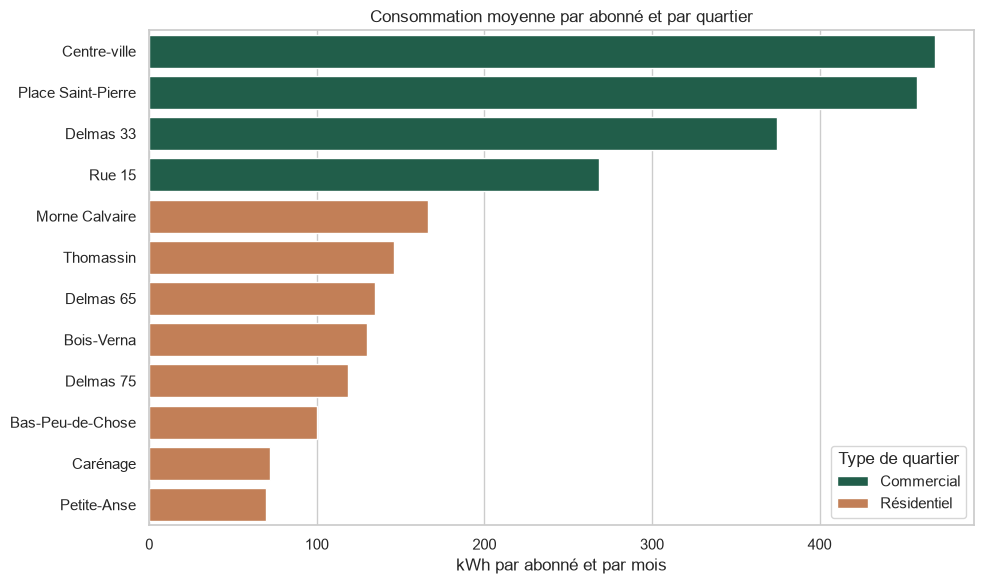

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
df_analyse = avec_meteo.copy()

moyenne_par_type = (
    df_analyse.groupby("type", as_index=False)["kwh_par_abonne"]
    .mean()
    .sort_values("kwh_par_abonne", ascending=False)
)
classement_quartiers = (
    df_analyse.groupby(["quartier", "type"], as_index=False)["kwh_par_abonne"]
    .mean()
    .sort_values("kwh_par_abonne", ascending=False)
    .reset_index(drop=True)
)
classement_quartiers.insert(0, "rang", range(1, len(classement_quartiers) + 1))

print("Consommation moyenne par abonné selon le type :")
display(moyenne_par_type.round({"kwh_par_abonne": 1}))
print("Classement des 12 quartiers :")
display(classement_quartiers.round({"kwh_par_abonne": 1}))

ordre_quartiers = classement_quartiers["quartier"].tolist()
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=classement_quartiers,
    x="kwh_par_abonne",
    y="quartier",
    hue="type",
    order=ordre_quartiers,
    hue_order=["Commercial", "Résidentiel"],
    dodge=False,
    palette={"Commercial": "#17684d", "Résidentiel": "#d47a45"},
    ax=ax,
)
ax.set_title("Consommation moyenne par abonné et par quartier")
ax.set_xlabel("kWh par abonné et par mois")
ax.set_ylabel("")
ax.legend(title="Type de quartier")
fig.tight_layout()
plt.show()

**Interprétation :** La moyenne commerciale atteint **393,2 kWh par abonné et par mois**, contre **117,4** dans les quartiers résidentiels, soit environ 3,35 fois plus. Centre-ville (468,7), Place Saint-Pierre (458,3) et Delmas 33 (374,4) forment le trio de tête; Petite-Anse est la plus basse (69,6). Il s'agit d'une moyenne par abonné : elle ne signifie pas que le total consommé par ces quartiers suit le même classement.

## 5. Comment la consommation évolue-t-elle, commune par commune ?

**13.** Tableau croisé : consommation totale par commune et par année, puis la hausse en % (calculée avant d'arrondir), puis les totaux en millions de kWh arrondis à 2. Puis la courbe de la consommation par abonné, mois par mois, pour chaque commune.

Attendu : Cap-Haïtien en tête, de 4.59 à 5.62 millions de kWh (+22.4 %) ; Delmas en dernier (+1.1 %) ; 4 courbes.

Consommation totale par commune et année, classée par hausse :


,2024 (millions de kWh),2025 (millions de kWh),Évolution (%)
commune,,,
Cap-Haïtien,4.59,5.62,22.46
Pétion-Ville,8.60,9.68,12.56
Port-au-Prince,10.09,10.31,2.27
Delmas,11.61,11.74,1.10


Consommation mensuelle par abonné : moyenne, minimum et maximum


,moyenne,minimum,maximum
commune,,,
Pétion-Ville,235.7,163.7,312.5
Port-au-Prince,174.5,78.5,230.5
Delmas,172.2,99.4,246.6
Cap-Haïtien,100.1,61.2,136.5


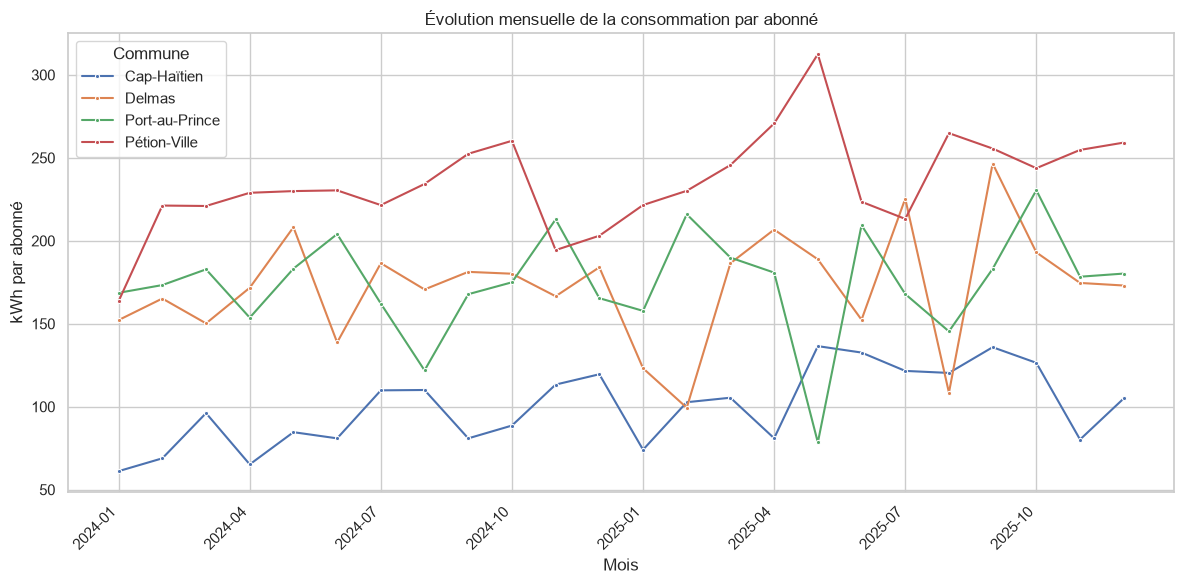

In [38]:
totaux_commune_annee = df_analyse.pivot_table(
    index="commune",
    columns="annee",
    values="kwh",
    aggfunc="sum",
)
evolution_commune = (
    (totaux_commune_annee[2025] - totaux_commune_annee[2024])
    / totaux_commune_annee[2024]
    * 100
)
tableau_evolution = pd.DataFrame(
    {
        "2024 (millions de kWh)": totaux_commune_annee[2024] / 1_000_000,
        "2025 (millions de kWh)": totaux_commune_annee[2025] / 1_000_000,
        "Évolution (%)": evolution_commune,
    }
).sort_values("Évolution (%)", ascending=False)
print("Consommation totale par commune et année, classée par hausse :")
display(tableau_evolution.round(2))

abonnes_par_commune = (
    df_analyse.groupby(["commune", "quartier"])["abonnes"]
    .first()
    .groupby("commune")
    .sum()
)
mensuel_commune = (
    df_analyse.groupby(["commune", "mois"], as_index=False)
    .agg(kwh_total=("kwh", "sum"))
)
mensuel_commune["kwh_par_abonne"] = (
    mensuel_commune["kwh_total"]
    / mensuel_commune["commune"].map(abonnes_par_commune)
)
resume_mensuel = (
    mensuel_commune.groupby("commune")["kwh_par_abonne"]
    .agg(moyenne="mean", minimum="min", maximum="max")
    .sort_values("moyenne", ascending=False)
    .round(1)
)
print("Consommation mensuelle par abonné : moyenne, minimum et maximum")
display(resume_mensuel)

ordre_mois = sorted(mensuel_commune["mois"].unique())
fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(
    data=mensuel_commune,
    x="mois",
    y="kwh_par_abonne",
    hue="commune",
    hue_order=sorted(mensuel_commune["commune"].unique()),
    marker="o",
    markersize=3,
    ax=ax,
)
ax.set_title("Évolution mensuelle de la consommation par abonné")
ax.set_xlabel("Mois")
ax.set_ylabel("kWh par abonné")
ax.set_xticks(range(0, len(ordre_mois), 3))
ax.set_xticklabels(ordre_mois[::3], rotation=45, ha="right")
ax.legend(title="Commune")
fig.tight_layout()
plt.show()
assert len(tableau_evolution) == 4
assert mensuel_commune["commune"].nunique() == 4

**Interprétation :** La consommation totale de Cap-Haïtien passe de **4,59** à **5,62 millions de kWh**, soit **+22,46 %** calculé avant l'arrondi; Delmas passe de **11,61** à **11,74 millions** (**+1,10 %**), la plus faible hausse. Pétion-Ville augmente de 12,56 % et Port-au-Prince de 2,27 %. Pour les courbes mensuelles, Pétion-Ville a la moyenne la plus élevée par abonné (235,7 kWh), contre 100,1 à Cap-Haïtien; les variations d'un mois à l'autre restent importantes.

## 6. La consommation suit-elle la chaleur, ou les heures de courant ?

**14.** Quartiers résidentiels seulement : nuage de points des heures de courant contre la consommation par abonné. Puis la corrélation de la consommation par abonné avec `heures_courant`, et avec `temperature_c`.

Attendu : 0.76 avec les heures de courant, -0.15 avec la température.

Quartiers résidentiels : consommation par abonné
Nombre de relevés : 186


,corrélation avec kwh_par_abonne
temperature_c,-0.15
heures_courant,0.76


Tous les quartiers : consommation totale en kWh


,corrélation avec kwh total
temperature_c,0.18
heures_courant,0.50


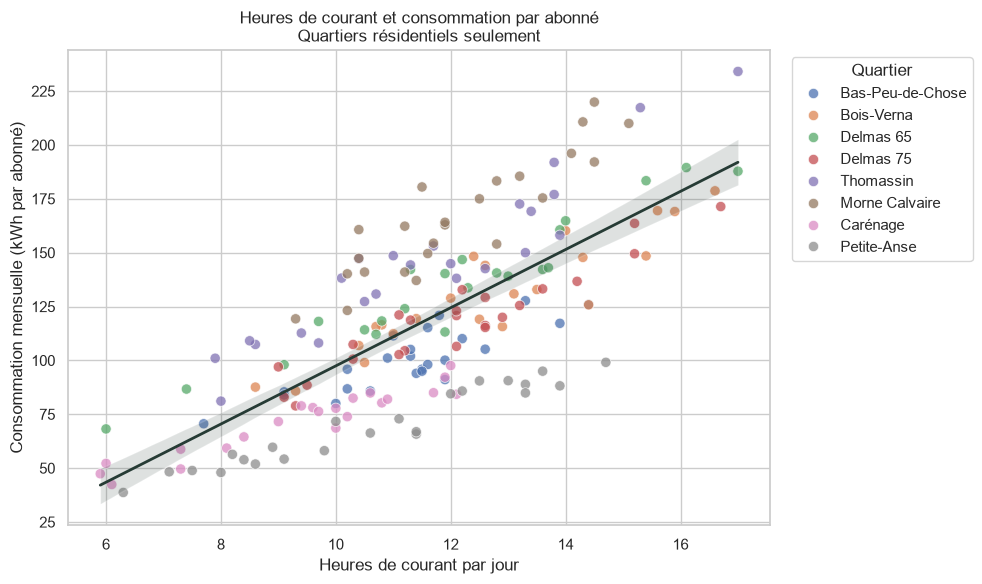

In [39]:
residentiel = df_analyse.loc[df_analyse["type"] == "Résidentiel"].copy()

correlations_attendues = residentiel[
    ["kwh_par_abonne", "temperature_c", "heures_courant"]
].corr()["kwh_par_abonne"].drop("kwh_par_abonne")
correlations_kwh_total = df_analyse[["kwh", "temperature_c", "heures_courant"]].corr()["kwh"].drop("kwh")

print("Quartiers résidentiels : consommation par abonné")
print("Nombre de relevés :", len(residentiel))
display(correlations_attendues.rename("corrélation avec kwh_par_abonne").to_frame().round(2))
print("Tous les quartiers : consommation totale en kWh")
display(correlations_kwh_total.rename("corrélation avec kwh total").to_frame().round(2))

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(
    data=residentiel,
    x="heures_courant",
    y="kwh_par_abonne",
    hue="quartier",
    alpha=0.75,
    s=55,
    ax=ax,
)
sns.regplot(
    data=residentiel,
    x="heures_courant",
    y="kwh_par_abonne",
    scatter=False,
    color="#263b35",
    line_kws={"linewidth": 2},
    ax=ax,
)
ax.set_title("Heures de courant et consommation par abonné\nQuartiers résidentiels seulement")
ax.set_xlabel("Heures de courant par jour")
ax.set_ylabel("Consommation mensuelle (kWh par abonné)")
ax.legend(title="Quartier", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()

**Interprétation :** Pour les **186 relevés résidentiels**, la corrélation entre les heures de courant et les kWh par abonné est de **0,76** : dans ces données, davantage d'heures de courant est associé à une consommation par abonné plus élevée. Celle entre température et kWh par abonné est faible et négative (**-0,15**); les résultats ne montrent donc pas de lien linéaire marqué avec la chaleur. Pour les kWh totaux de tous les quartiers, les coefficients sont différents : **0,50** avec les heures et **0,18** avec la température, car les totaux reflètent aussi la taille et le type des quartiers. Une corrélation décrit une association, pas une cause.

## 7. Où les coupures sont-elles les plus longues ?

**15.** Les heures de courant : médiane, Q1, Q3 par commune, puis un histogramme pour Cap-Haïtien. Combien de relevés de 2025 ont moins de 8 heures de courant par jour, et dans quels quartiers ?

Attendu : médiane de 10.0 heures à Cap-Haïtien, entre 11.6 et 11.9 ailleurs ; 3 relevés de 2025, à Carénage, Delmas 33 et Rue 15.

Heures de courant par commune : médiane, premier et troisième quartiles


,mediane,q1,q3
commune,,,
Cap-Haïtien,10.0,8.3,11.7
Delmas,11.9,10.1,13.0
Port-au-Prince,11.6,10.7,13.1
Pétion-Ville,11.6,10.4,13.0


Relevés de 2025 avec moins de 8 heures par jour : 3


,mois,quartier,commune,heures_courant
81,2025-01,Delmas 33,Delmas,7.4
227,2025-08,Carénage,Cap-Haïtien,7.3
253,2025-11,Rue 15,Cap-Haïtien,5.9


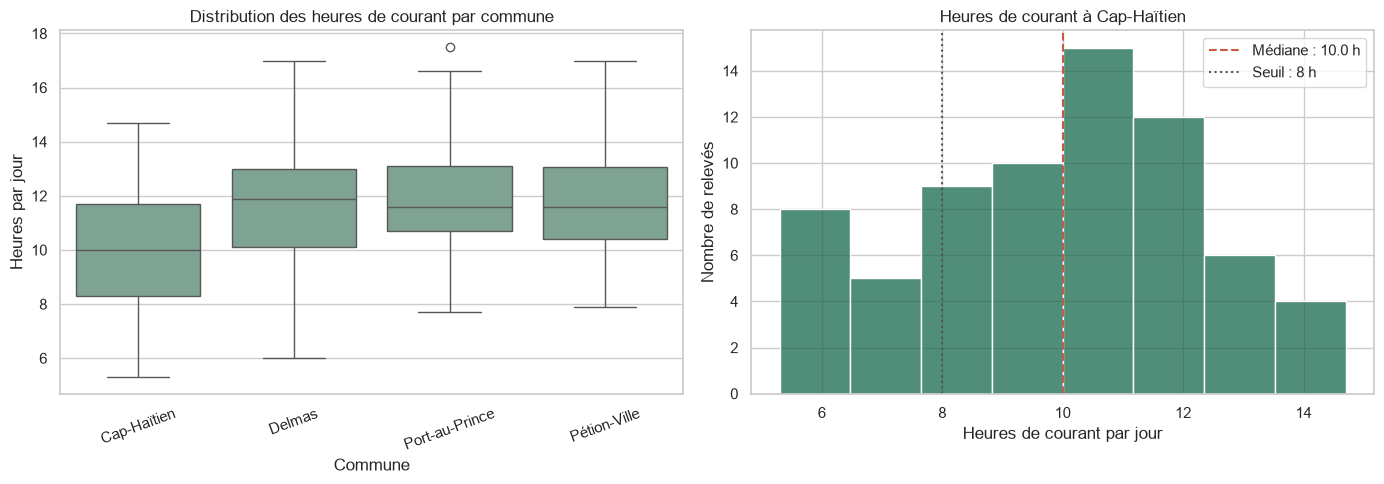

In [40]:
ordre_communes = sorted(df_analyse["commune"].unique())
resume_heures = (
    df_analyse.groupby("commune")["heures_courant"]
    .agg(
        mediane="median",
        q1=lambda valeurs: valeurs.quantile(0.25),
        q3=lambda valeurs: valeurs.quantile(0.75),
    )
    .reindex(ordre_communes)
)
print("Heures de courant par commune : médiane, premier et troisième quartiles")
display(resume_heures.round(1))

cap_haïtien = df_analyse.loc[df_analyse["commune"] == "Cap-Haïtien"]
relevés_faibles_2025 = df_analyse.loc[
    (df_analyse["annee"] == 2025) & (df_analyse["heures_courant"] < 8),
    ["mois", "quartier", "commune", "heures_courant"],
].sort_values(["mois", "quartier"])
print("Relevés de 2025 avec moins de 8 heures par jour :", len(relevés_faibles_2025))
display(relevés_faibles_2025)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(
    data=df_analyse,
    x="commune",
    y="heures_courant",
    order=ordre_communes,
    color="#78a992",
    ax=axes[0],
)
axes[0].set_title("Distribution des heures de courant par commune")
axes[0].set_xlabel("Commune")
axes[0].set_ylabel("Heures par jour")
axes[0].tick_params(axis="x", rotation=20)

sns.histplot(
    data=cap_haïtien,
    x="heures_courant",
    bins=8,
    color="#17684d",
    ax=axes[1],
)
axes[1].axvline(
    cap_haïtien["heures_courant"].median(),
    color="#c65a43",
    linestyle="--",
    label=f"Médiane : {cap_haïtien['heures_courant'].median():.1f} h",
)
axes[1].axvline(8, color="#555555", linestyle=":", label="Seuil : 8 h")
axes[1].set_title("Heures de courant à Cap-Haïtien")
axes[1].set_xlabel("Heures de courant par jour")
axes[1].set_ylabel("Nombre de relevés")
axes[1].legend()
fig.tight_layout()
plt.show()
assert len(resume_heures) == 4
assert len(relevés_faibles_2025) == 3

**Interprétation :** Cap-Haïtien a la médiane la plus basse, **10,0 heures de courant par jour** (Q1 = 8,3; Q3 = 11,7), contre 11,6 à 11,9 heures dans les trois autres communes. En 2025, trois relevés passent sous 8 heures : Delmas 33 en janvier (7,4 h), Carénage en août (7,3 h) et Rue 15 en novembre (5,9 h). Ces relevés signalent moins d'heures de courant; ils ne donnent pas à eux seuls la durée exacte de chaque coupure.

## 8. Quels relevés sortent du lot ?

**16.** Les 3 plus grosses consommations de tout le fichier : mois, quartier, type, kwh.

Attendu : Delmas 33 en 2025-07 (742780), Centre-ville en 2024-11 (597730), Delmas 33 en 2025-09 (591420).

Trois plus fortes consommations du tableau final :


,mois,quartier,type,kwh
0,2025-07,Delmas 33,Commercial,742780
1,2024-11,Centre-ville,Commercial,597730
2,2025-09,Delmas 33,Commercial,591420


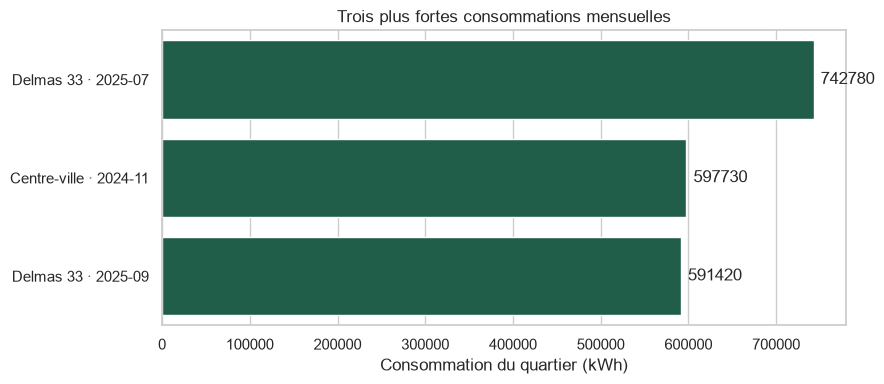

In [41]:
top3_releves = (
    df_analyse.nlargest(3, "kwh")[["mois", "quartier", "type", "kwh"]]
    .reset_index(drop=True)
)
top3_releves["releve"] = top3_releves["quartier"] + " · " + top3_releves["mois"]
print("Trois plus fortes consommations du tableau final :")
display(top3_releves[["mois", "quartier", "type", "kwh"]])

fig, ax = plt.subplots(figsize=(9, 4))
bars = sns.barplot(
    data=top3_releves,
    x="kwh",
    y="releve",
    color="#17684d",
    ax=ax,
)
ax.bar_label(bars.containers[0], fmt="%.0f", padding=5)
ax.set_title("Trois plus fortes consommations mensuelles")
ax.set_xlabel("Consommation du quartier (kWh)")
ax.set_ylabel("")
fig.tight_layout()
plt.show()
assert len(top3_releves) == 3
assert top3_releves["kwh"].is_monotonic_decreasing

**Interprétation :** Les trois relevés les plus élevés sont tous commerciaux : Delmas 33 atteint **742 780 kWh** en juillet 2025 et **591 420 kWh** en septembre 2025; Centre-ville atteint **597 730 kWh** en novembre 2024. Ce sont des consommations totales de quartier pour un mois, à distinguer des valeurs par abonné présentées à la question 4.

## 9. Conclusion

En trois phrases, répondez au directeur : la consommation suit-elle la chaleur, ou les heures de courant ? Citez vos chiffres, et dites ce qu'une corrélation ne permet pas de conclure.

**Conclusion au directeur :** Dans les quartiers résidentiels, la consommation mensuelle par abonné est davantage associée aux heures de courant (corrélation `r = 0,76`) qu'à la température (`r = -0,15`); sur les kWh totaux des 12 quartiers, les corrélations mesurées sont respectivement `0,50` avec les heures et `0,18` avec la température. Les quartiers commerciaux affichent en moyenne `393,2 kWh` par abonné contre `117,4` dans les quartiers résidentiels, Centre-ville (468,7), Place Saint-Pierre (458,3) et Delmas 33 (374,4) sont les plus élevés, tandis que Petite-Anse (69,6) et Carénage (72,2) sont les plus faibles; de 2024 à 2025, la hausse communale varie de `1,10 %` à Delmas à `22,46 %` à Cap-Haïtien. Ces résultats décrivent 279 relevés mensuels sur deux ans, après exclusion de 9 consommations manquantes, et ne prouvent pas qu'une variable cause l'autre; la compagnie devrait suivre les coupures avec des mesures plus fréquentes, vérifier en priorité les besoins des quartiers commerciaux très consommateurs et améliorer la complétude des relevés météo et de consommation.

## Et maintenant : le tableau de bord

Le directeur ne lit pas de notebook : il ouvre un lien. La suite se fait dans `app.py`, en six étapes, avec `uv run streamlit run app.py` ouvert à côté. Les étapes sont dans le README.